# The Forest Went Quiet

Run the cells in order: **explore → edit → check**.
See [task_description.md](task_description.md) for the objective and rules.

## 1. Explore

Expand the recording list, then choose an index in the next cell.

In [1]:
%matplotlib inline
import torch
from challenge_model import CLASS_NAMES, load_model, predict_probabilities
from investigation_tools import (
    load_recordings, show_recordings, inspect_recording, show_table,
)

torch.set_num_threads(2)
model = load_model()
recordings, rows = load_recordings()
show_recordings(rows, predict_probabilities(model, recordings))

Loaded 31 recordings: 13 failures and 18 references.


Index,Recording,Correct label,Status,Model prediction
0,clip-115891f2426ec60a,frogs,misclassified,rain
1,clip-129d8bc480c5ec14,rain,correct,rain
2,clip-1e35382499fd018d,birds,correct,birds
3,clip-32e2e6dc8e4e481d,frogs,correct,frogs
4,clip-36a6b63a6c9f6254,insects,misclassified,rain
5,clip-4a6957467538e6ca,rain,correct,rain
6,clip-4ec96931cba73b2c,birds,correct,birds
7,clip-56c2ae84706e976e,frogs,correct,frogs
8,clip-573fdb8b6caf8c47,birds,misclassified,rain
9,clip-603dfa8b06bc0218,rain,correct,rain


clip-115891f2426ec60a — correct label: frogs


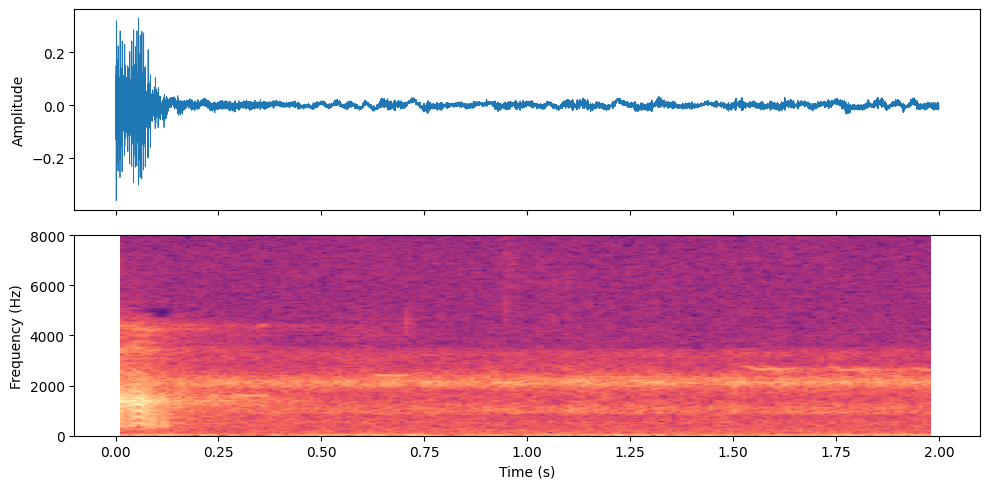

Class,Probability
birds,0.0%
frogs,0.0%
insects,0.0%
rain,99.9%


In [2]:
recording_index = 0  # Change this to explore another recording.
inspect_recording(recordings, rows, model, index=recording_index)

## 2. Edit your solution

Edit `transform(audio)` below; keep your imports and helpers in this cell.
Input and output are `float32` arrays of shape `(B, 32000)`.
Use only the standard library, NumPy, and SciPy.

Running this cell writes or replaces **`main.py`**. The starter returns unchanged audio.

In [3]:
%%writefile main.py
import numpy as np


def transform(audio):
    # Add your approach here.
    return audio.copy()


def main():
    with np.load("test-input.npz", allow_pickle=False) as data:
        audio = data["audio"]
        sample_rate = data["sample_rate"]
        clip_ids = data["clip_ids"]
    np.savez("test-output.npz", audio=transform(audio),
             sample_rate=sample_rate, clip_ids=clip_ids)


if __name__ == "__main__":
    main()

Writing main.py


## 3. Check and submit

Try your saved transformation on the example audio, then check the
audio limits and compare predictions. All class probabilities are
available in `before` and `after`.

In [4]:
from runpy import run_path
import numpy as np
from audio_io import validate

transform = run_path("main.py")["transform"]
with np.load("train-input.npz", allow_pickle=False) as data:
    original = data["audio"]
    clip_ids = data["clip_ids"]
    modified = transform(original.copy())
    edit_percent = validate(original, modified)
    np.savez("candidate.npz", audio=modified,
             sample_rate=data["sample_rate"], clip_ids=clip_ids)

before = predict_probabilities(model, original)
after = predict_probabilities(model, modified)
print("Audio shape, dtype, and preservation checks passed.")
show_table(
    ["Recording", "Before", "After", "Edit energy (limit: 1%)"],
    [(clip_id, CLASS_NAMES[np.argmax(p)], CLASS_NAMES[np.argmax(q)], f"{energy:.3f}%")
     for clip_id, p, q, energy in zip(clip_ids, before, after, edit_percent)],
)

Audio shape, dtype, and preservation checks passed.


Recording,Before,After,Edit energy (limit: 1%)
clip-1e35382499fd018d,birds,birds,0.000%
clip-8e095dc64dc2aa15,birds,birds,0.000%
clip-32e2e6dc8e4e481d,frogs,frogs,0.000%
clip-6f23722a067bc48b,frogs,frogs,0.000%
clip-ca0337dae80c211d,insects,insects,0.000%
clip-6232e05c686338ae,insects,insects,0.000%
clip-d985805b8b0c22a5,rain,rain,0.000%
clip-836a4170cb53474f,rain,rain,0.000%


After each edit, rerun steps 2–3. Upload **[main.py](main.py)** when ready.
Local checks do not guarantee a flag; unchanged audio does not solve the task.